# Phase 13 baseline comparison — detection-only vs. fixed-response vs. full system

Loads `evaluation/phase13_baseline_comparison.json`, the report
`backend/app/evaluation/run_baseline_comparison.py` actually produced the
last time it was run, and reproduces its key comparison as a chart and a
table.

**What this is:** a real, already-computed report, not a live re-run of
the evaluation — re-running it yourself is `cd backend && python -m
app.evaluation.run_baseline_comparison` (see `docs/reproducibility.md`).

**What the data actually is:** every number below comes from
`backend/app/cybersecurity/synthetic_data.py`'s *synthetic* stand-in
dataset — no real CICIoMT2024 data has been used anywhere in this project
(see `datasets/LICENSE_NOTES.md` and `docs/limitations-and-ethics.md` §3).
Treat this as "what this architecture does on a controlled synthetic
benchmark," not a field-measured result.

**Requires:** `pandas`, `matplotlib` (`pip install pandas matplotlib`, or
just the backend venv's `requirements.txt` plus those two — neither is
currently a backend dependency, since nothing under `backend/app/` needs a
plotting library). Run from the repository root, or adjust `REPORT_PATH`
below.

In [1]:
import json
from pathlib import Path

import pandas as pd

REPORT_PATH = Path("evaluation/phase13_baseline_comparison.json")
if not REPORT_PATH.exists():
    # Notebook may be run from notebooks/ directly.
    REPORT_PATH = Path("..") / REPORT_PATH

with open(REPORT_PATH) as f:
    report = json.load(f)

print("generated_at:", report["generated_at"])
print("data_source:", report["data_source"])
print("training_seed:", report["training_seed"], "| device_context_seed:", report["device_context_seed"])
print("models:", list(report["models"].keys()))

generated_at: 2026-10-13T04:12:44.211159+00:00
data_source: SYNTHETIC stand-in dataset (not real CICIoMT2024 -- see datasets/LICENSE_NOTES.md)
training_seed: 42 | device_context_seed: 2026
models: ['random_forest', 'xgboost']


## Unsafe autonomous action rate, by system and model

This is the headline finding: on trials where a real attack hit a HIGH-criticality, patient-dependent device, how often did each system autonomously execute a disruptive action anyway (unsafe), versus route it to human approval?

In [2]:
rows = []
for model_name, model_report in report["models"].items():
    for system_name, system_report in model_report["systems"].items():
        unsafe = system_report["unsafe_autonomous_action_rate"]
        rows.append({
            "model": model_name,
            "system": system_name,
            "unsafe_rate": unsafe["rate"],
            "unsafe_numerator": unsafe["numerator"],
            "unsafe_denominator": unsafe["denominator"],
            "autonomous_executions": system_report["autonomous_executions"],
            "awaiting_human_approval": system_report["awaiting_human_approval"],
        })

df = pd.DataFrame(rows)
df

,model,system,unsafe_rate,unsafe_numerator,unsafe_denominator,autonomous_executions,awaiting_human_approval
0,random_forest,detection_only,0.0,0,162,0,0
1,random_forest,fixed_response,1.0,162,162,1035,0
2,random_forest,detection_plus_agentic_ai,0.0,0,162,524,511
3,random_forest,detection_plus_risk_engine,1.0,162,162,1035,0
4,random_forest,full_system,0.0,0,162,524,511
5,xgboost,detection_only,0.0,0,162,0,0
6,xgboost,fixed_response,1.0,162,162,1037,0
7,xgboost,detection_plus_agentic_ai,0.0,0,162,526,511
8,xgboost,detection_plus_risk_engine,1.0,162,162,1037,0
9,xgboost,full_system,0.0,0,162,526,511


## Chart: unsafe-autonomous-action rate, full system vs. the naive baseline

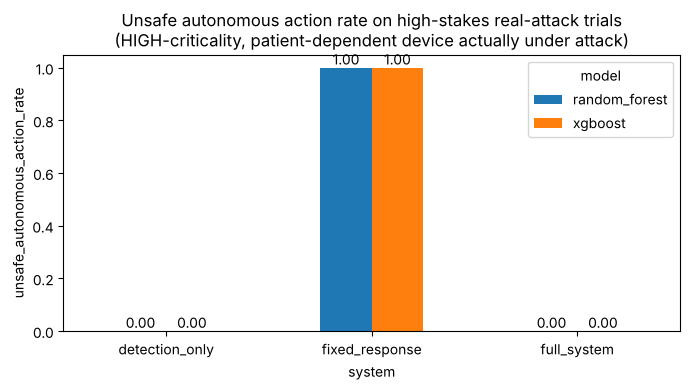

In [3]:
import matplotlib.pyplot as plt

pivot = df.pivot(index="system", columns="model", values="unsafe_rate")
# Keep a fixed, readable system order rather than whatever dict/JSON order
# happened to produce, if all three systems are present in this report.
order = [s for s in ["detection_only", "fixed_response", "full_system"] if s in pivot.index]
pivot = pivot.loc[order]

ax = pivot.plot(kind="bar", figsize=(7, 4), rot=0)
ax.set_ylabel("unsafe_autonomous_action_rate")
ax.set_ylim(0, 1.05)
ax.set_title("Unsafe autonomous action rate on high-stakes real-attack trials\n(HIGH-criticality, patient-dependent device actually under attack)")
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f")
plt.tight_layout()
plt.show()

## Reading the result

If `full_system`'s bar is at (or near) 0.0 and `fixed_response`'s is at (or near) 1.0, that reproduces this project's central claim: a naive, non-patient-aware response baseline autonomously disrupts a patient-dependent, high-criticality device on nearly every real attack against it, while the real Risk Engine + Policy Engine routes those same trials to human approval instead — generalizing Scenario B (`docs/architecture.md` §17) from two fixed test cases to every high-stakes trial in the held-out split.

`unnecessary_isolation_rate` (not charted above) may show `null` for every system/model in this report — a disclosed dataset limitation, not a missing feature: see `evaluation/README.md` and `docs/limitations-and-ethics.md` §3 for why (the synthetic dataset's classes are cleanly separated enough that both detectors measured zero false positives on their held-out split).

In [4]:
unnecessary = []
for model_name, model_report in report["models"].items():
    for system_name, system_report in model_report["systems"].items():
        u = system_report["unnecessary_isolation_rate"]
        unnecessary.append({
            "model": model_name, "system": system_name,
            "unnecessary_isolation_rate": u["rate"],
            "numerator": u["numerator"], "denominator": u["denominator"],
        })
pd.DataFrame(unnecessary)

,model,system,unnecessary_isolation_rate,numerator,denominator
0,random_forest,detection_only,None,0,0
1,random_forest,fixed_response,None,0,0
2,random_forest,detection_plus_agentic_ai,None,0,0
3,random_forest,detection_plus_risk_engine,None,0,0
4,random_forest,full_system,None,0,0
5,xgboost,detection_only,None,0,0
6,xgboost,fixed_response,None,0,0
7,xgboost,detection_plus_agentic_ai,None,0,0
8,xgboost,detection_plus_risk_engine,None,0,0
9,xgboost,full_system,None,0,0
